# ECE 3715 Mini-Project 2
## Continuous Random Variables

**Christian Ruelas (Partner A): Steps 1, 2 & 4**  
**Arun Nambiar (Partner B): Steps 3 & 5**  
**Ibrahim Elsousi (Partner C): Steps 6, 7 & 8**  
**Seed: 1274601137 — drawn once on November 2, 2026; do not change.**

Steps 1 and 2 cover distribution and inversion experiments; Step 3 covers a function of a random variable.
Step 4 compares Rayleigh and Pareto moments. Step 5 measures convergence to the Gaussian. Steps 6–8 apply these results to Gaussian and envelope detection and operating-point selection. Each completed step contains derivations, numerical checks,
and a figure followed by an interpretation. Differences mean estimate minus theory.

In [1]:
from time import perf_counter
START = perf_counter()
from pathlib import Path
import sys
import numpy as np
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh,
                    sample_by_inversion, ks_statistic, q_function)

SEED = 1274601137  # drawn 2026-11-02, do not change
rng = np.random.default_rng(SEED)
# Create once here in this order. Reserve all later streams for the team.
rng1 = rng.spawn(1)[0]
rng2 = rng.spawn(1)[0]
rng3 = rng.spawn(1)[0]
rng4 = rng.spawn(1)[0]
rng5 = rng.spawn(1)[0]
rng6 = rng.spawn(1)[0]
rng7 = rng.spawn(1)[0]
rng8 = rng.spawn(1)[0]

FIGDIR = Path('figures')
FIGDIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': .22, 'axes.spines.top': False})

def table(headers, rows):
    def fmt(x):
        return f'{x:.7g}' if isinstance(x, (float, np.floating)) else str(x)
    display(Markdown('| ' + ' | '.join(headers) + ' |\n|' +
                     '|'.join(['---'] * len(headers)) + '|\n' +
                     '\n'.join('| ' + ' | '.join(fmt(x) for x in row) + ' |' for row in rows)))

def finish(fig, name):
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'Seed: {SEED}')
print(f'Python {sys.version.split()[0]}, NumPy {np.__version__}, '
      f'SciPy {scipy.__version__}, Matplotlib {matplotlib.__version__}')

Seed: 1274601137
Python 3.13.18, NumPy 2.4.6, SciPy 1.16.3, Matplotlib 3.10.0


### Helper checks
Check the inverse endpoints, non-unit parameters, and a tiny positive uniform input.
Cross-check the custom KS statistic against SciPy, including tied observations,
to verify that both sides of each empirical-CDF jump are measured.
These checks consume none of the eight simulation streams.

In [2]:
assert inv_cdf_exponential(0, 2) == 0
assert inv_cdf_rayleigh(0, 3) == 0
assert np.isposinf(inv_cdf_exponential(1, 2))
assert np.isposinf(inv_cdf_rayleigh(1, 3))
u_check = np.array([0., 1e-16, .25, .75, np.nextafter(1., 0.)])
assert np.allclose(inv_cdf_exponential(u_check, 2), stats.expon.ppf(u_check, scale=.5))
assert np.allclose(inv_cdf_rayleigh(u_check, 3), stats.rayleigh.ppf(u_check, scale=3))
assert inv_cdf_exponential(1e-16, 1) > 0
for x_check in [np.array([.1, .4, .9]), np.array([.2, .2, .8]), np.array([.6])]:
    assert np.isclose(ks_statistic(x_check, stats.uniform.cdf),
                      stats.kstest(x_check, stats.uniform.cdf).statistic)
print('Inverse-CDF endpoint/parameter checks and KS cross-checks passed.')

Inverse-CDF endpoint/parameter checks and KS cross-checks passed.


## Step 1 — From CDF to density

For a continuous random variable, $F(x)=P(X\leq x)$ and $f(x)=F'(x)$ wherever
the derivative exists. Values assigned to a density at individual endpoints do not affect probabilities.

**Uniform on $[0,1]$ (support $[0,1]$):**
$$F(x)=\begin{cases}0&x<0\\x&0\leq x\leq1\\1&x>1,\end{cases}
\qquad f(x)=\begin{cases}1&0\leq x\leq1\\0&\text{otherwise}.\end{cases}$$

**Exponential with rate $\lambda=1$ (support $[0,\infty)$):**
$$F(x)=\begin{cases}0&x<0\\1-e^{-\lambda x}&x\geq0,\end{cases}
\qquad f(x)=\begin{cases}\lambda e^{-\lambda x}&x\geq0\\0&x<0.\end{cases}$$

**Standard Gaussian (support $\mathbb R$):**
$$F(x)=\Phi(x)=\frac12\left[1+\operatorname{erf}\left(\frac{x}{\sqrt2}\right)\right],
\qquad f(x)=\frac{e^{-x^2/2}}{\sqrt{2\pi}}.$$

**Rayleigh with scale $\sigma=1$ (support $[0,\infty)$):**
$$F(x)=\begin{cases}0&x<0\\1-e^{-x^2/(2\sigma^2)}&x\geq0,\end{cases}
\qquad f(x)=\begin{cases}\dfrac{x}{\sigma^2}e^{-x^2/(2\sigma^2)}&x\geq0\\0&x<0.\end{cases}$$

Generate $N=10^5$ observations of each distribution with NumPy's library generators.
For sorted samples $x_{(i)}$, the two-sided KS statistic checks both sides of every jump:
$$D_N=\max_i\left\{\frac{i}{N}-F(x_{(i)}),\ F(x_{(i)})-\frac{i-1}{N}\right\}.$$
The approximate 95% critical value is $1.36/\sqrt{10^5}=0.0043007$.
A statistic below the cutoff means the test does not reject the specified distribution;
it does not prove the distributions are identical. Parameters here are specified, not fitted.

| Distribution | N | KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| Uniform [0,1] | 100000 | 0.003370311 | 0.004300698 | Do not reject |
| Exponential, rate 1 | 100000 | 0.001765445 | 0.004300698 | Do not reject |
| Standard Gaussian | 100000 | 0.003454166 | 0.004300698 | Do not reject |
| Rayleigh, scale 1 | 100000 | 0.002428224 | 0.004300698 | Do not reject |

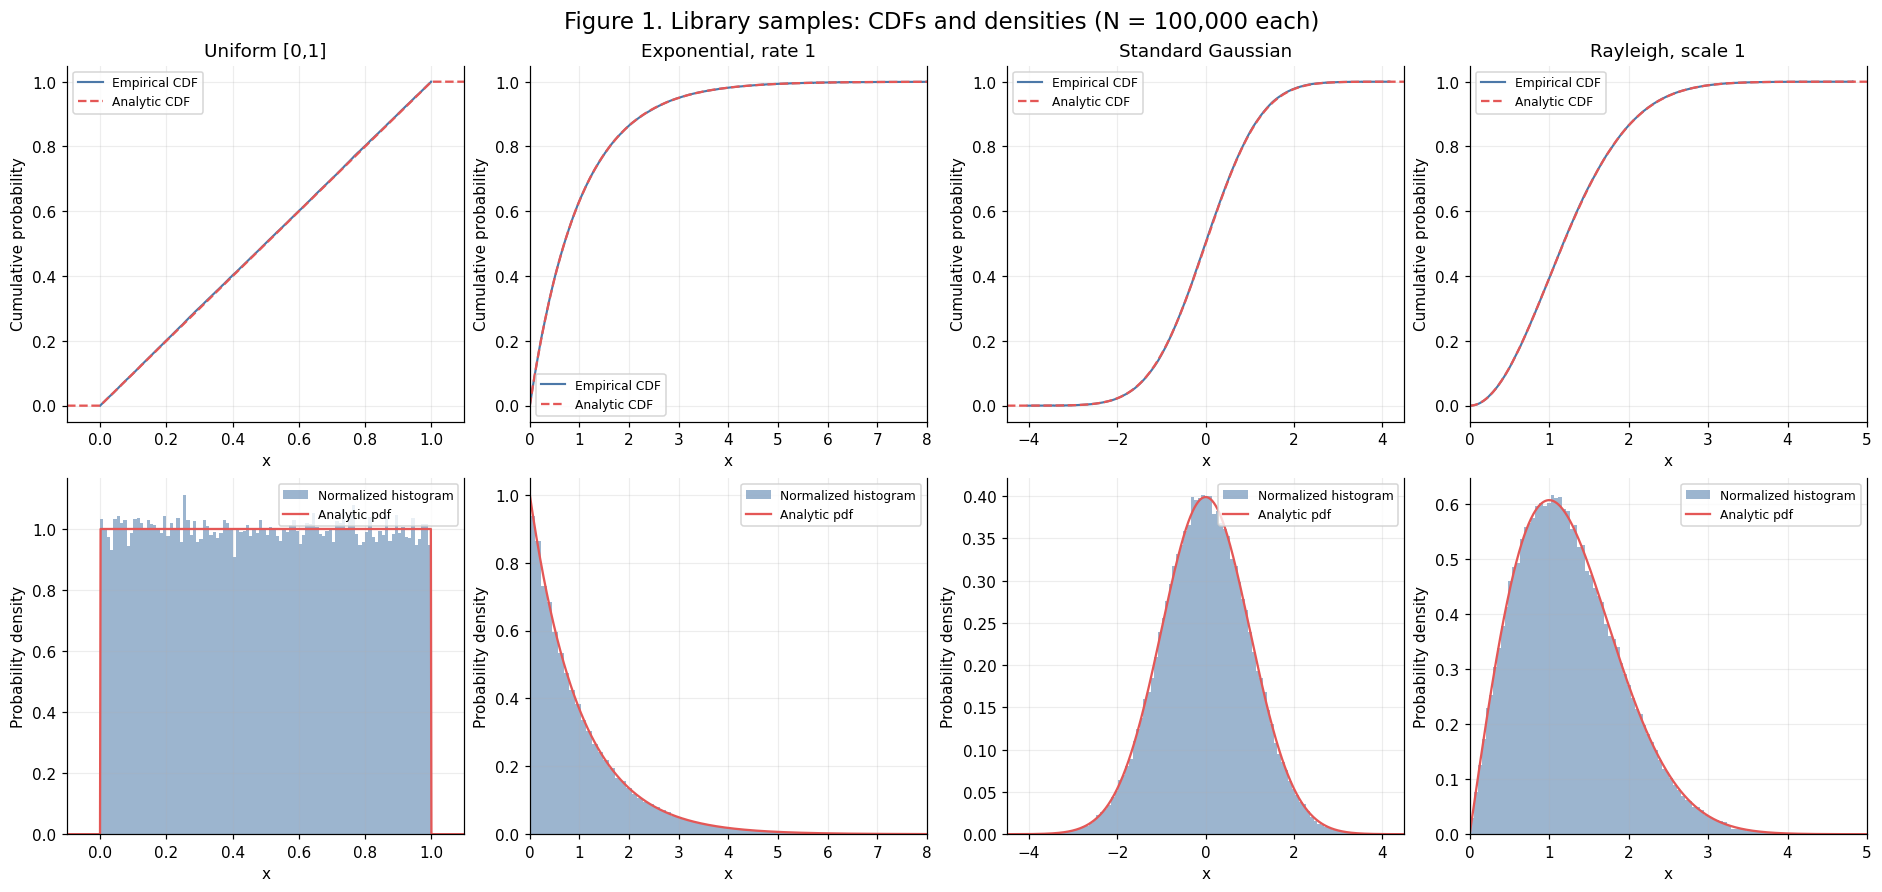

In [3]:
N1 = 100_000
critical1 = 1.36 / np.sqrt(N1)
distributions1 = [
    ('Uniform [0,1]', rng1.uniform(0, 1, N1), stats.uniform(), (-.1, 1.1)),
    ('Exponential, rate 1', rng1.exponential(1, N1), stats.expon(), (0, 8)),
    ('Standard Gaussian', rng1.standard_normal(N1), stats.norm(), (-4.5, 4.5)),
    ('Rayleigh, scale 1', rng1.rayleigh(1, N1), stats.rayleigh(), (0, 5)),
]
rows1 = []
fig, axes = plt.subplots(2, 4, figsize=(17, 8), layout='constrained')
for col, (name, samples, law, bounds) in enumerate(distributions1):
    d = ks_statistic(samples, law.cdf)
    rows1.append([name, N1, d, critical1, 'Do not reject' if d < critical1 else 'Reject'])
    x = np.linspace(*bounds, 700)
    ordered = np.sort(samples)
    axes[0, col].step(ordered, np.arange(1, N1 + 1) / N1, where='post',
                      lw=1.4, color='#4c78a8', label='Empirical CDF')
    axes[0, col].plot(x, law.cdf(x), '--', color='#e45756', label='Analytic CDF')
    axes[0, col].set(title=name, xlabel='x', ylabel='Cumulative probability', xlim=bounds)
    axes[0, col].legend(fontsize=8)
    axes[1, col].hist(samples, bins=100, density=True, color='#4c78a8', alpha=.55,
                      label='Normalized histogram')
    axes[1, col].plot(x, law.pdf(x), color='#e45756', label='Analytic pdf')
    axes[1, col].set(xlabel='x', ylabel='Probability density', xlim=bounds)
    axes[1, col].legend(fontsize=8)
fig.suptitle('Figure 1. Library samples: CDFs and densities (N = 100,000 each)', fontsize=15)
table(['Distribution', 'N', 'KS D', '95% cutoff', 'Decision'], rows1)
finish(fig, 'figure_01')

All four tests in Figure 1 do not reject their specified CDFs: the uniform, exponential, Gaussian, and Rayleigh KS distances are respectively **0.0033703, 0.0017654, 0.0034542, and 0.0024282**, each below the **0.0043007** cutoff at $N=10^5$.
The empirical and analytic curves are nearly superimposed at this scale, but visual overlap
alone cannot distinguish a small distributional error from sampling noise.
The exponential density peaks at the left boundary and has a long right tail;
the Rayleigh density starts at zero and rises to a mode at $x=1$.
The plotted windows focus on the bulk of the data; KS uses every observation and
the histograms are normalized using all observations, including the tails outside those windows.

### Exponential and Rayleigh moments

The six closed forms (with $\lambda=\sigma=1$ in this experiment) are

| Distribution | Mean | Median | Variance |
|---|---|---|---|
| Exponential | $1/\lambda=1$ | $\ln2/\lambda\approx0.693147$ | $1/\lambda^2=1$ |
| Rayleigh | $\sigma\sqrt{\pi/2}\approx1.253314$ | $\sigma\sqrt{2\ln2}\approx1.177410$ | $(2-\pi/2)\sigma^2\approx0.429204$ |

Use the arithmetic mean, sample median, and unbiased sample variance (`ddof=1`).
The exponential mean-to-median ratio is $1/\ln2\approx1.4427$ because its right-skewed density
has a long upper tail that pulls the mean above the point splitting the probability in half.
The Gaussian density is symmetric about zero, so its mean and median coincide at zero.

In [4]:
moment_rows1 = []
for index, theory in [(1, [1., np.log(2), 1.]),
                       (3, [np.sqrt(np.pi/2), np.sqrt(2*np.log(2)), 2-np.pi/2])]:
    name, samples, _, _ = distributions1[index]
    estimates = [np.mean(samples), np.median(samples), np.var(samples, ddof=1)]
    for quantity, estimate, exact in zip(['Mean', 'Median', 'Variance'], estimates, theory):
        moment_rows1.append([name, quantity, estimate, exact, estimate-exact])
table(['Distribution', 'Quantity', 'Estimate', 'Closed form', 'Difference'], moment_rows1)
print(f'Exponential theoretical mean/median = {1 / np.log(2):.7f}')

| Distribution | Quantity | Estimate | Closed form | Difference |
|---|---|---|---|---|
| Exponential, rate 1 | Mean | 1.00032 | 1 | 0.0003203091 |
| Exponential, rate 1 | Median | 0.6928037 | 0.6931472 | -0.000343495 |
| Exponential, rate 1 | Variance | 1.001347 | 1 | 0.001346822 |
| Rayleigh, scale 1 | Mean | 1.25254 | 1.253314 | -0.0007740946 |
| Rayleigh, scale 1 | Median | 1.175111 | 1.17741 | -0.002298586 |
| Rayleigh, scale 1 | Variance | 0.428195 | 0.4292037 | -0.001008695 |

Exponential theoretical mean/median = 1.4426950


## Step 2 — Build your own generator by inversion

### Inversion result and proof
Let $U\sim\operatorname{Uniform}(0,1)$ and let $F$ be continuous and strictly increasing
on its support. For $x$ in that support, monotonicity gives the two-line proof
$$P(F^{-1}(U)\leq x)=P(U\leq F(x)),$$
$$P(U\leq F(x))=F(x).$$
Outside the support the CDF is respectively zero or one, so the result extends to all real $x$.
The endpoint events have probability zero for an ideal continuous uniform variable.

### Derive the inverse CDFs
For the exponential distribution,
$$u=1-e^{-\lambda x}\ \Longrightarrow\ 1-u=e^{-\lambda x}
\ \Longrightarrow\ \ln(1-u)=-\lambda x
\ \Longrightarrow\ F^{-1}(u)=-\frac{\ln(1-u)}{\lambda}.$$
For the Rayleigh distribution,
$$u=1-e^{-x^2/(2\sigma^2)}\ \Longrightarrow\ \ln(1-u)=-\frac{x^2}{2\sigma^2}
\ \Longrightarrow\ x^2=-2\sigma^2\ln(1-u)
\ \Longrightarrow\ F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}.$$
The positive square root is required because Rayleigh samples are nonnegative.

### Endpoint and numerical handling
Both implementations use `log1p(-u)` to evaluate $\ln(1-u)$ accurately near zero.
Exactly $u=0$ maps to $x=0$, which belongs to both supports; no clipping or rejection is needed.
The inverse accepts $u=1$ and returns $+\infty$, the correct limiting quantile,
but `rng.random()` samples $[0,1)$ and therefore never supplies that endpoint.
Invalid probabilities and nonpositive or nonfinite parameters raise `ValueError`.
Both $-\ln(1-U)/\lambda$ and $-\ln U/\lambda$ have the same exponential distribution because
$1-U$ is also uniform in the continuous model; we use the first form so a returned zero stays finite.

### Verification plan
Use only `rng2.random()` through `sample_by_inversion` for the Step 2 samples.
Compare each inversion sample to its analytic CDF, then to the independent **Step 1 library
sample** with a two-sample KS test. This reuses the library reference without calling
`rng.exponential` or `rng.rayleigh` in Step 2. For two samples of sizes $n$ and $m$,
the approximate 95% cutoff is $1.36\sqrt{(n+m)/(nm)}=0.0060821$ when both are $10^5$.

| Distribution | N | Inversion KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| Exponential, rate 1 | 100000 | 0.003825903 | 0.004300698 | Do not reject |
| Rayleigh, scale 1 | 100000 | 0.002079102 | 0.004300698 | Do not reject |

| Distribution | Library vs analytic D | Inversion vs library D | Two-sample cutoff | Two-sample decision |
|---|---|---|---|---|
| Exponential, rate 1 | 0.001765445 | 0.00425 | 0.006082105 | Do not reject |
| Rayleigh, scale 1 | 0.002428224 | 0.00417 | 0.006082105 | Do not reject |

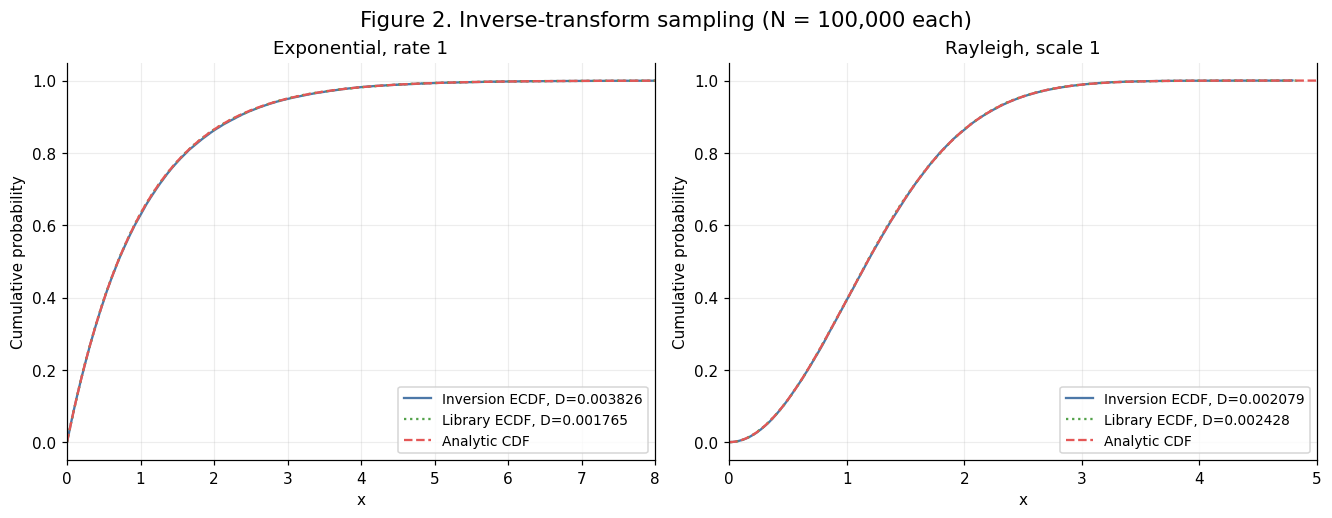

In [5]:
N2 = 100_000
critical2 = 1.36 / np.sqrt(N2)
inversion2 = [
    ('Exponential, rate 1', sample_by_inversion(inv_cdf_exponential, N2, rng2, lam=1),
     distributions1[1][1], stats.expon(), (0, 8)),
    ('Rayleigh, scale 1', sample_by_inversion(inv_cdf_rayleigh, N2, rng2, sigma=1),
     distributions1[3][1], stats.rayleigh(), (0, 5)),
]
rows2 = []
comparison_rows2 = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
for ax, (name, samples, reference, law, bounds) in zip(axes, inversion2):
    d = ks_statistic(samples, law.cdf)
    d_ref = ks_statistic(reference, law.cdf)
    d_two = stats.ks_2samp(samples, reference).statistic
    cutoff_two = 1.36 * np.sqrt((samples.size + reference.size) / (samples.size * reference.size))
    rows2.append([name, N2, d, critical2, 'Do not reject' if d < critical2 else 'Reject'])
    comparison_rows2.append([name, d_ref, d_two, cutoff_two,
                             'Do not reject' if d_two < cutoff_two else 'Reject'])
    ordered = np.sort(samples)
    ax.step(ordered, np.arange(1, N2 + 1) / N2, where='post', color='#4c78a8',
            label=f'Inversion ECDF, D={d:.6f}')
    ref_ordered = np.sort(reference)
    ax.step(ref_ordered, np.arange(1, reference.size + 1) / reference.size, where='post',
            color='#54a24b', ls=':', label=f'Library ECDF, D={d_ref:.6f}')
    x = np.linspace(*bounds, 700)
    ax.plot(x, law.cdf(x), '--', color='#e45756', label='Analytic CDF')
    ax.set(title=name, xlabel='x', ylabel='Cumulative probability', xlim=bounds)
    ax.legend(fontsize=9)
fig.suptitle('Figure 2. Inverse-transform sampling (N = 100,000 each)', fontsize=14)
table(['Distribution', 'N', 'Inversion KS D', '95% cutoff', 'Decision'], rows2)
table(['Distribution', 'Library vs analytic D', 'Inversion vs library D',
       'Two-sample cutoff', 'Two-sample decision'], comparison_rows2)
finish(fig, 'figure_02')

Figure 2 shows the inverse-transform ECDF alongside the analytic CDF and the independent
library ECDF. The first table compares inversion to the exact distribution and the second
compares the two sampling methods with the appropriate two-sample cutoff.
The test decisions apply to this frozen seed; a correctly implemented generator can still
exceed a 95% cutoff by chance, so the seed must never be redrawn to improve a result.
The Rayleigh square root spreads out small positive quantiles relative to the exponential,
consistent with its density vanishing at zero instead of peaking there.

For this run the exponential inversion gives **D = 0.0038259** and the Rayleigh inversion gives **D = 0.0020791**, both below **0.0043007**. Against independent library samples the two-sample distances are **0.0042500** and **0.0041700**, below **0.0060821**; neither test rejects at the approximate 5% level. These checks support the inverse formulas with numerical evidence rather than relying on the overlapping curves.

## Step 3 — A function of a random variable

### CDF of $Y=X^2$
Let $X\sim\mathcal N(0,1)$ with CDF $\Phi$ and density $\varphi$, and let $Y=X^2\geq 0$.
For $y\leq 0$, $F_Y(y)=0$ (and $F_Y(0)=P(X=0)=0$). For $y>0$, squaring is undone by a two-sided interval:
$$Y\leq y\iff X^2\leq y\iff -\sqrt y\leq X\leq\sqrt y.$$
$$F_Y(y)=P(-\sqrt y\leq X\leq\sqrt y)=\Phi(\sqrt y)-\Phi(-\sqrt y).$$
By symmetry $\Phi(-\sqrt y)=1-\Phi(\sqrt y)$, so
$$F_Y(y)=2\Phi(\sqrt y)-1,\qquad y>0.$$

### Density of $Y$
Differentiate with the chain rule, using $\Phi'=\varphi$ and $\frac{d}{dy}\sqrt y=\frac{1}{2\sqrt y}$:
$$f_Y(y)=\frac{d}{dy}\bigl[2\Phi(\sqrt y)-1\bigr]=2\varphi(\sqrt y)\cdot\frac{1}{2\sqrt y}=\frac{\varphi(\sqrt y)}{\sqrt y}.$$
Substituting $\varphi(\sqrt y)=e^{-y/2}/\sqrt{2\pi}$,
$$\boxed{f_Y(y)=\frac{1}{\sqrt{2\pi y}}\,e^{-y/2},\qquad y>0,}$$
and $f_Y(y)=0$ for $y<0$. This is the chi-square density with one degree of freedom.

### Why the density diverges but still integrates to 1
Near the origin $e^{-y/2}\to1$, so $f_Y(y)\approx(2\pi y)^{-1/2}\to\infty$ as $y\to0^+$.
The map $x\mapsto x^2$ has slope $2x\to0$ at the origin, so it is flat there:
a slab $|X|\leq\epsilon$ carries probability $\approx 2\epsilon\varphi(0)$ but lands in the thin interval
$0\leq Y\leq\epsilon^2$. Probability per unit length is therefore $\approx 2\epsilon\varphi(0)/\epsilon^2\propto 1/\epsilon=y^{-1/2}$, which grows without bound.
The total mass stays finite because $y^{-1/2}$ is integrable at zero:
$$P(Y\leq\delta)=\int_0^\delta\frac{dy}{\sqrt{2\pi y}}\,e^{-y/2}\approx\frac{2\sqrt\delta}{\sqrt{2\pi}}\to0\quad(\delta\to0),$$
and the exact value is $P(Y\leq\delta)=2\Phi(\sqrt\delta)-1\to0$. The same chain rule gives $\int_0^\infty f_Y=F_Y(\infty)-F_Y(0)=1$.

### Log-log slope
For small $y$, $\ln f_Y(y)\approx-\tfrac12\ln y-\tfrac12\ln(2\pi)$, a straight line of **slope $-1/2$** on log-log axes.
The exponent comes from the Jacobian $|dx/dy|=1/(2\sqrt y)$ of the inverse map $x=\sqrt y$.

### Analytic targets
$$P[Y\leq1]=2\Phi(1)-1,\qquad P[Y\leq0.1]=2\Phi(\sqrt{0.1})-1,\qquad m=\bigl(\Phi^{-1}(0.75)\bigr)^2,$$
since $2\Phi(\sqrt m)-1=\tfrac12\iff\Phi(\sqrt m)=0.75$. For the moments, $E[Y]=E[X^2]=1$ and
$$\operatorname{Var}(Y)=E[X^4]-(E[X^2])^2=3-1=2.$$
The fourth central moment of $Y$ is $E[(Y-1)^4]=60$ (chi-square, 1 degree of freedom), which gives the standard error of the sample variance, $\sqrt{(60-2^2)/N}$.
The median's standard error is $1/(2f_Y(m)\sqrt N)$.

### Verification plan
Draw $N=10^6$ standard Gaussians from `rng3`, square them, and compare the sample CDF with $F_Y$ using the KS statistic and the 95% cutoff $1.36/\sqrt N$.
**Binning choice:** log-spaced bins, 10 per decade from $10^{-6}$ to the sample maximum, because a uniform width of 0.5 puts the whole divergence in the first bar.
Histogram heights are counts divided by $N\times$(bin width), so they are densities; the $\approx 10^{-3}$ of samples below $10^{-6}$ still count in $N$.
The integral check uses `scipy.integrate.quad` with an algebraic endpoint weight $y^{-1/2}$ on $(0,1]$ to handle the singularity exactly, and the plain integrand on $[1,\infty)$.

Density integral: 0.6826894921 on (0,1] + 0.3173105079 on [1,inf) = 1.0000000000


| δ | Exact P(Y ≤ δ) | Approx 2√δ/√(2π) | f_Y(δ) |
|---|---|---|---|
| 0.1 | 0.2481704 | 0.2523133 | 1.200039 |
| 0.01 | 0.07965567 | 0.07978846 | 3.969525 |
| 0.0001 | 0.007978713 | 0.007978846 | 39.89223 |
| 1e-06 | 0.0007978844 | 0.0007978846 | 398.9421 |

| Test | N | KS D vs derived CDF | 95% cutoff | KS D vs scipy chi2(1) | Decision |
|---|---|---|---|---|---|
| Y = X² | 1000000 | 0.0009189483 | 0.00136 | 0.0009189483 | Do not reject |

| Quantity | Empirical | Theory | Difference | Std. error | Diff / SE |
|---|---|---|---|---|---|
| P[Y ≤ 1] | 0.682239 | 0.6826895 | -0.0004504921 | 0.0004654294 | -0.9679064 |
| P[Y ≤ 0.1] | 0.248191 | 0.2481704 | 2.063405e-05 | 0.0004319512 | 0.04776939 |
| Median | 0.4554059 | 0.4549364 | 0.0004695133 | 0.001061264 | 0.4424094 |
| Mean | 1.000613 | 1 | 0.0006133975 | 0.001414214 | 0.4337376 |
| Variance | 1.994066 | 2 | -0.005933742 | 0.007483315 | -0.7929297 |

| Log-log slope (y < 0.01) | Fitted | Theory | Difference |
|---|---|---|---|
| Histogram | -0.4959056 | -0.5 | 0.004094388 |

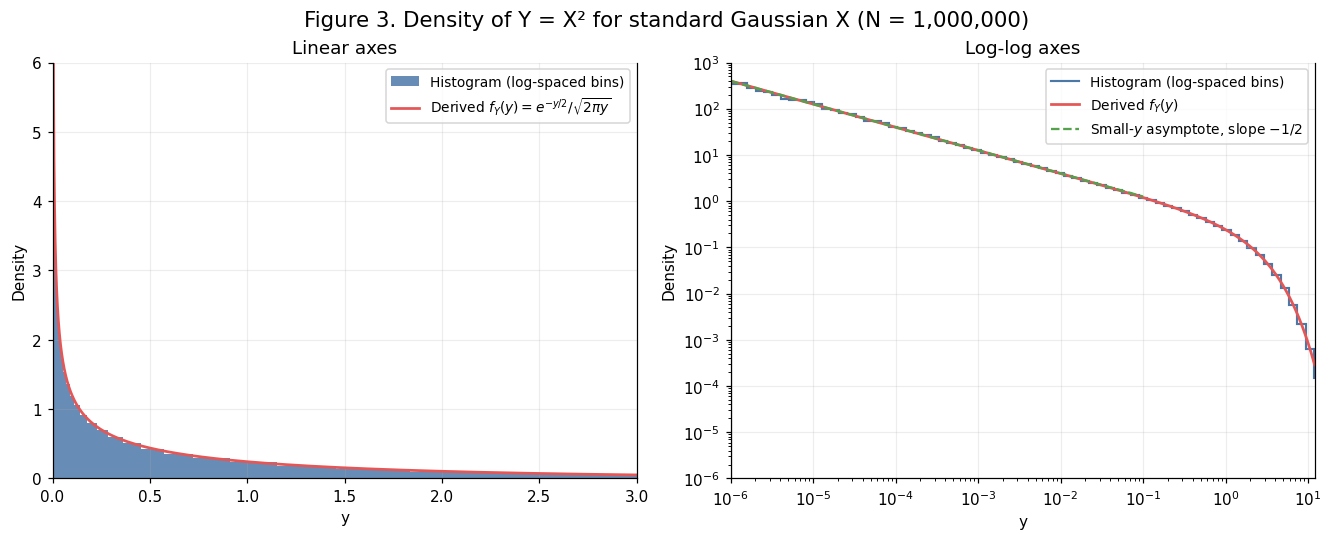

In [6]:
N3 = 1_000_000
critical3 = 1.36 / np.sqrt(N3)
x3 = rng3.standard_normal(N3)
y3 = x3 ** 2
law3 = stats.chi2(1)

def cdf_y(y):
    return 2 * stats.norm.cdf(np.sqrt(y)) - 1

def pdf_y(y):
    return np.exp(-y / 2) / np.sqrt(2 * np.pi * y)

# Density integrates to 1 despite the divergence: y^(-1/2) weight on (0, 1], plain on [1, inf)
from scipy.integrate import quad
head, head_err = quad(lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi), 0, 1, weight='alg', wvar=(-0.5, 0))
tail, tail_err = quad(pdf_y, 1, np.inf)
integral3 = head + tail
mass_rows = [[f'{d:g}', cdf_y(d), 2 * np.sqrt(d) / np.sqrt(2 * np.pi), pdf_y(d)]
             for d in (1e-1, 1e-2, 1e-4, 1e-6)]

# KS goodness of fit of the squared samples against the derived CDF
d3 = ks_statistic(y3, cdf_y)
d3_lib = ks_statistic(y3, law3.cdf)

# Log-spaced histogram normalized to a density (counts / (N * width))
edges = np.geomspace(1e-6, y3.max(), int(10 * np.log10(y3.max() / 1e-6)) + 1)
counts, _ = np.histogram(y3, bins=edges)
widths = np.diff(edges)
hist_density = counts / (N3 * widths)
centers = np.sqrt(edges[:-1] * edges[1:])
# bin-wise exact density: bin probability / width (what the histogram estimates)
exact_bin_density = np.diff(cdf_y(edges)) / widths

# Empirical log-log slope over bins with y < 0.01 (counts large enough to be reliable)
small = (centers < 1e-2) & (counts >= 30)
slope_fit = np.polyfit(np.log(centers[small]), np.log(hist_density[small]), 1)
slope3 = slope_fit[0]
slope_theory = -0.5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
grid = np.geomspace(1e-6, 12, 3000)
ax = axes[0]
ax.stairs(hist_density, edges, color='#4c78a8', alpha=.85, fill=True, label='Histogram (log-spaced bins)')
ax.plot(grid, pdf_y(grid), color='#e45756', lw=1.8, label=r'Derived $f_Y(y)=e^{-y/2}/\sqrt{2\pi y}$')
ax.set(title='Linear axes', xlabel='y', ylabel='Density', xlim=(0, 3), ylim=(0, 6))
ax.legend(fontsize=9)
ax = axes[1]
ax.stairs(hist_density, edges, color='#4c78a8', lw=1.4, label='Histogram (log-spaced bins)')
ax.plot(grid, pdf_y(grid), color='#e45756', lw=1.8, label=r'Derived $f_Y(y)$')
ref = grid[grid < 1e-1]
ax.plot(ref, 1 / np.sqrt(2 * np.pi * ref), '--', color='#54a24b', lw=1.5,
        label=r'Small-$y$ asymptote, slope $-1/2$')
ax.set(title='Log-log axes', xlabel='y', ylabel='Density', xscale='log', yscale='log',
       xlim=(1e-6, 12), ylim=(1e-6, 1e3))
ax.legend(fontsize=9)
fig.suptitle('Figure 3. Density of Y = X² for standard Gaussian X (N = 1,000,000)', fontsize=14)

# Probabilities, median, mean, variance with standard errors
m_theory = stats.norm.ppf(0.75) ** 2
rows3 = []
for name, thr in [('P[Y ≤ 1]', 1.0), ('P[Y ≤ 0.1]', 0.1)]:
    p = cdf_y(thr)
    est = np.mean(y3 <= thr)
    se = np.sqrt(p * (1 - p) / N3)
    rows3.append([name, est, p, est - p, se, (est - p) / se])
m_est = np.median(y3)
se_m = 1 / (2 * pdf_y(m_theory) * np.sqrt(N3))
rows3.append(['Median', m_est, m_theory, m_est - m_theory, se_m, (m_est - m_theory) / se_m])
mean_est, var_est = y3.mean(), y3.var(ddof=1)
se_mean = np.sqrt(2 / N3)
se_var = np.sqrt((60 - 2 ** 2) / N3)
rows3.append(['Mean', mean_est, 1.0, mean_est - 1, se_mean, (mean_est - 1) / se_mean])
rows3.append(['Variance', var_est, 2.0, var_est - 2, se_var, (var_est - 2) / se_var])

print(f'Density integral: {head:.10f} on (0,1] + {tail:.10f} on [1,inf) = {integral3:.10f}')
table(['δ', 'Exact P(Y ≤ δ)', 'Approx 2√δ/√(2π)', 'f_Y(δ)'], mass_rows)
table(['Test', 'N', 'KS D vs derived CDF', '95% cutoff', 'KS D vs scipy chi2(1)', 'Decision'],
      [['Y = X²', N3, d3, critical3, d3_lib, 'Do not reject' if d3 < critical3 else 'Reject']])
table(['Quantity', 'Empirical', 'Theory', 'Difference', 'Std. error', 'Diff / SE'], rows3)
table(['Log-log slope (y < 0.01)', 'Fitted', 'Theory', 'Difference'],
      [['Histogram', slope3, slope_theory, slope3 - slope_theory]])
finish(fig, 'figure_03')

Figure 3 overlays the density-normalized histogram on the derived $f_Y$. The left panel shows the spike at the origin and the rapid decay by $y\approx3$; the right panel shows the same data on log-log axes, where the divergence is a straight line. The log-spaced bins, 10 per decade from $10^{-6}$, resolve the region near zero that a uniform width of 0.5 would collapse into a single bar. The fitted histogram slope for $y<0.01$ is **-0.4959**, against the theoretical **-1/2**; the slope comes from the Jacobian $1/(2\sqrt y)$ of the inverse map $x=\sqrt y$, i.e. the flat squaring map compressing probability near $x=0$.

The density integrates to **1.0000000000** numerically (**0.6826895** on $(0,1]$ plus **0.3173105** on $[1,\infty)$), so the divergence is integrable. The mass inside $[0,\delta]$ shrinks like $2\sqrt{\delta/(2\pi)}$ (**0.0007979** at $\delta=10^{-6}$) even though $f_Y(10^{-6})=$ **398.94**. The KS distance to the derived CDF is **D = 0.0009189**, below the 95% cutoff **0.00136**, so the sample does not reject $F_Y$. As before, this decision applies to the frozen seed.

All five quantities are within **one standard error** of theory (|difference/SE| ≤ **0.97**), using $N=10^6$ trials: $P[Y\leq1]=$ **0.682239** (theory 0.6826895, SE 0.000465), $P[Y\leq0.1]=$ **0.248191** (theory 0.2481704, SE 0.000432), median **0.455406** (theory 0.4549364), mean **1.000613**, variance **1.994066**. The median **0.4549** is less than half the mean **1**: the unbounded density at the origin packs much of the probability near zero, while the long right tail (the squares of large Gaussians) pulls the mean up.

## Step 4 — Expectation and moments

For a Rayleigh variable $R$ with scale 1, substitute $t=r^2/2$, $dt=r\,dr$:
$$E[R^k]=\int_0^\infty r^k r e^{-r^2/2}\,dr
=2^{k/2}\int_0^\infty t^{k/2} e^{-t}\,dt
=2^{k/2}\Gamma(1+k/2).$$
The first four raw moments are $\sqrt{\pi/2}$, $2$, $3\sqrt{\pi/2}$, and $8$.
The estimator is the average of $R_i^k$, so its standard error is
$$\operatorname{SE}(\widehat m_k)=\sqrt{\frac{E[R^{2k}]-E[R^k]^2}{N}}.$$
We report the signed difference divided by this standard error. The Rayleigh variance is $2-\pi/2$.

For a Pareto variable $P$ with shape $3/2$ and scale 1, $f_P(x)=\tfrac32 x^{-5/2}$ for $x\ge1$. The first moment exists:
$$E[P]=\tfrac32\int_1^\infty x^{-3/2}\,dx
=\tfrac32[-2x^{-1/2}]_1^\infty=3.$$
The second moment diverges:
$$E[P^2]=\tfrac32\int_1^\infty x^{-1/2}\,dx
=\lim_{b\to\infty}3(\sqrt b-1)=\infty.$$
Since the mean is finite and the second moment is infinite, the population variance is infinite. NumPy's Pareto generator uses the Lomax form starting at zero, so adding 1 gives the required support starting at 1.

Draw one million observations from each distribution using the reserved Step 4 generator. At each checkpoint, use a longer prefix of the same sample and compute sample variance with `ddof=1`.

Rayleigh raw moments (N = 1,000,000)


| Order k | Estimate | Theory | Difference | SE | Difference / SE |
|---|---|---|---|---|---|
| 1 | 1.252943 | 1.253314 | -0.0003714598 | 0.0006551364 | -0.5669961 |
| 2 | 1.998654 | 2 | -0.001346061 | 0.002 | -0.6730304 |
| 3 | 3.75591 | 3.759942 | -0.004032168 | 0.005819178 | -0.6929101 |
| 4 | 7.987747 | 8 | -0.01225306 | 0.01788854 | -0.6849669 |

| N | Rayleigh mean | Rayleigh variance | Pareto mean | Pareto variance |
|---|---|---|---|---|
| 1,000 | 1.243982 | 0.4030108 | 2.588102 | 12.88022 |
| 10,000 | 1.249135 | 0.432654 | 3.007792 | 435.0296 |
| 100,000 | 1.254116 | 0.4298967 | 3.07765 | 1857.445 |
| 1,000,000 | 1.252943 | 0.428789 | 3.040459 | 3225.936 |

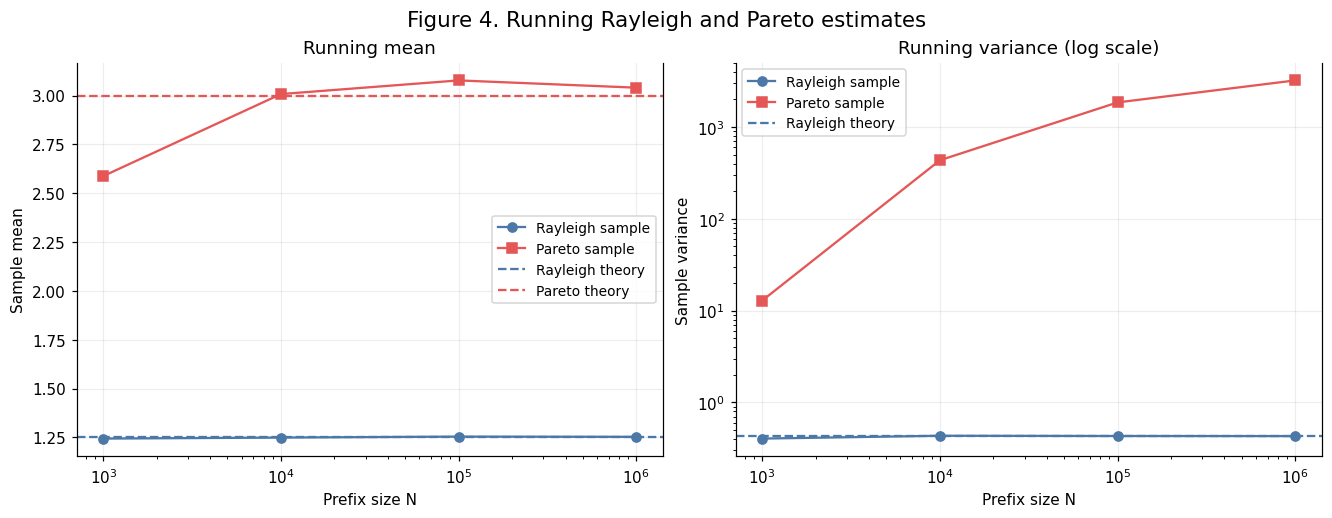

In [7]:
from scipy.special import gamma

N4 = 1_000_000
rayleigh4 = rng4.rayleigh(scale=1, size=N4)
pareto4 = 1 + rng4.pareto(a=1.5, size=N4)
orders4 = np.arange(1, 5)
moments4 = 2.0 ** (orders4 / 2) * gamma(1 + orders4 / 2)
se4 = np.sqrt((2.0 ** orders4 * gamma(1 + orders4) - moments4**2) / N4)
estimates4 = np.array([np.mean(rayleigh4**k) for k in orders4])
diff4 = estimates4 - moments4
print(f'Rayleigh raw moments (N = {N4:,})')
table(['Order k', 'Estimate', 'Theory', 'Difference', 'SE', 'Difference / SE'],
      list(zip(orders4, estimates4, moments4, diff4, se4, diff4 / se4)))

checkpoints4 = [1_000, 10_000, 100_000, N4]

def prefix_stats4(samples):
    return np.array([(samples[:n].mean(), samples[:n].var(ddof=1)) for n in checkpoints4])

rayleigh_stats4 = prefix_stats4(rayleigh4)
pareto_stats4 = prefix_stats4(pareto4)
table(['N', 'Rayleigh mean', 'Rayleigh variance', 'Pareto mean', 'Pareto variance'],
      [[f'{n:,}', *r, *p] for n, r, p in zip(checkpoints4, rayleigh_stats4, pareto_stats4)])
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
for col4, ax4 in enumerate(axes4):
    ax4.semilogx(checkpoints4, rayleigh_stats4[:, col4], 'o-', color='#4c78a8', label='Rayleigh sample')
    ax4.semilogx(checkpoints4, pareto_stats4[:, col4], 's-', color='#e45756', label='Pareto sample')
    ax4.axhline((moments4[0], 2-np.pi/2)[col4], ls='--', color='#4c78a8', label='Rayleigh theory')
    if col4 == 0:
        ax4.axhline(3, ls='--', color='#e45756', label='Pareto theory')
    else:
        ax4.set_yscale('log')
    ax4.set(xlabel='Prefix size N', ylabel=('Sample mean', 'Sample variance')[col4],
            title=('Running mean', 'Running variance (log scale)')[col4])
    ax4.legend(fontsize=9)
fig4.suptitle('Figure 4. Running Rayleigh and Pareto estimates', fontsize=14)
finish(fig4, 'figure_04')

Figure 4 compares each estimate across four increasing sample sizes. The Rayleigh mean and variance stay close to theory. The Pareto mean settles near 3 because the first moment is finite, while rare large draws can shift the variance sharply because squared deviations give those draws so much weight.

In this run the Pareto mean ends at **3.0405**, while the sample variance grows from **12.88** at 1,000 observations to **3,225.94** at one million. This exceeds the assignment’s rough range of tens to hundreds; the fixed seed produces rare large values, and the model has no finite variance to constrain the estimate. All four Rayleigh moments are within **0.70 standard errors** of their theoretical values.

The sample variance is a finite number because it averages a finite set of finite squared deviations. For this Pareto distribution, it describes the spread of the observed sample, including whichever extremes happened to be drawn, and does not estimate a finite population variance.

**Practical rule:** Before reporting an error bar of $s/\sqrt N$, check that the measurement model has finite variance and that a few extremes are not driving the estimate. When the variance is infinite, justify a different uncertainty method or report a robust quantity such as the median with a suitable interval.

## Step 5 — The central limit theorem, and where it fails

### Standardizing a sum of uniforms
Let $U_i\sim\operatorname{Uniform}(0,1)$ be independent with $E[U_i]=\tfrac12$ and $\operatorname{Var}(U_i)=\tfrac1{12}$. For $S_N=U_1+\cdots+U_N$,
$$E[S_N]=\frac N2,\qquad \operatorname{Var}(S_N)=\frac N{12}\ \Longrightarrow\ Z_N=\frac{S_N-N/2}{\sqrt{N/12}}$$
has mean 0 and variance 1. Variances add because the summands are independent.
By the central limit theorem $Z_N\to\mathcal N(0,1)$ in distribution; the KS distance $D_N=\sup_z|F_{Z_N}(z)-\Phi(z)|$ measures how far along it is.
Because the uniform distribution is symmetric, its third cumulant is zero, so the leading $N^{-1/2}$ Edgeworth correction vanishes. The first nonzero correction is of order $N^{-1}$, consistent with the observed convergence rate.
We also compute the **exact** distance from the Irwin–Hall CDF of $S_N$, which separates the true gap from sampling noise.

### Pareto summands
For Pareto shape $3/2$ and scale 1, $E[P]=3$ but $\operatorname{Var}(P)=\infty$ (Step 4), so the standardization above is undefined. We center with the true mean $3N$ and divide by the **sample standard deviation** of the $2\times10^5$ sums at each $N$, since no finite theoretical scale exists.
The sample scale is dominated by a few extreme sums, which is part of what the experiment exposes.

### Procedure
Draw $2\times10^5$ independent sums for each $N$ from `rng5`: first the six uniform cases, then the four Pareto cases (drawn in chunks of 5,000 sums to bound memory). The 95% KS cutoff is $1.36/\sqrt{2\times10^5}=0.0030411$.
To test the stable-law claim below, compare the Pareto sums at $N=100$ and $N=1000$ after scaling by $N^{1/2}$ (the Gaussian scale) and by $N^{1/\alpha}=N^{2/3}$ (the stable scale, $\alpha=3/2$) using a two-sample KS test.

| N | Mean of sum | Variance of sum | KS D vs N(0,1) | Exact distance | 95% cutoff | Decision |
|---|---|---|---|---|---|---|
| 1 | 0.5 | 0.08333333 | 0.05842895 | 0.05720672 | 0.003041052 | Reject |
| 2 | 1 | 0.1666667 | 0.01723267 | 0.01643079 | 0.003041052 | Reject |
| 3 | 1.5 | 0.25 | 0.00958711 | 0.009853142 | 0.003041052 | Reject |
| 5 | 2.5 | 0.4166667 | 0.006562889 | 0.005713299 | 0.003041052 | Reject |
| 10 | 5 | 0.8333333 | 0.00482235 | 0.002813207 | 0.003041052 | Reject |
| 30 | 15 | 2.5 | 0.001704078 | 0.0009243075 | 0.003041052 | Do not reject |

| N | Mean of sum | Scale used (sample SD) | KS D vs N(0,1) | 95% cutoff | Decision |
|---|---|---|---|---|---|
| 1 | 3 | 15.42762 | 0.4484267 | 0.003041052 | Reject |
| 10 | 30 | 65.7151 | 0.3938786 | 0.003041052 | Reject |
| 100 | 300 | 551.8412 | 0.4177979 | 0.003041052 | Reject |
| 1000 | 3000 | 1643.854 | 0.3593933 | 0.003041052 | Reject |

| Comparison, N = 100 vs N = 1000 | Two-sample KS D | 95% cutoff |
|---|---|---|
| Scaled by N^(1/2) | 0.22212 | 0.004300698 |
| Scaled by N^(2/3) | 0.041215 | 0.004300698 |

Fitted log-log slope of the exact uniform distance against N: -1.171.


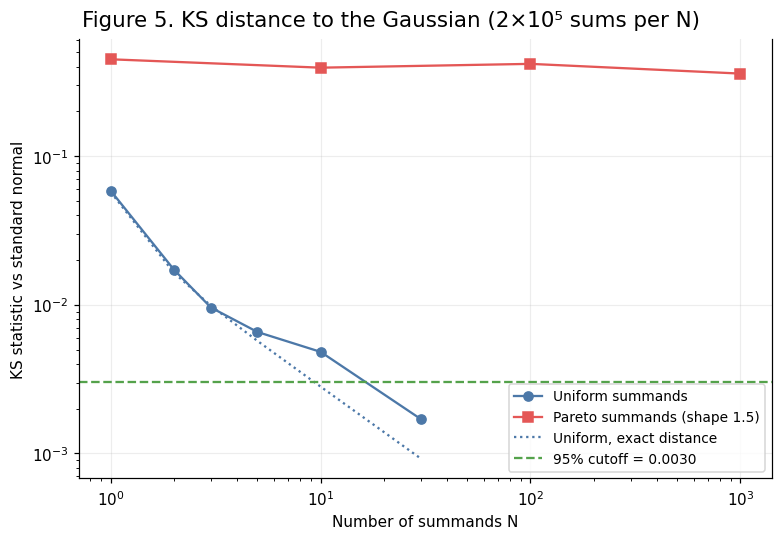

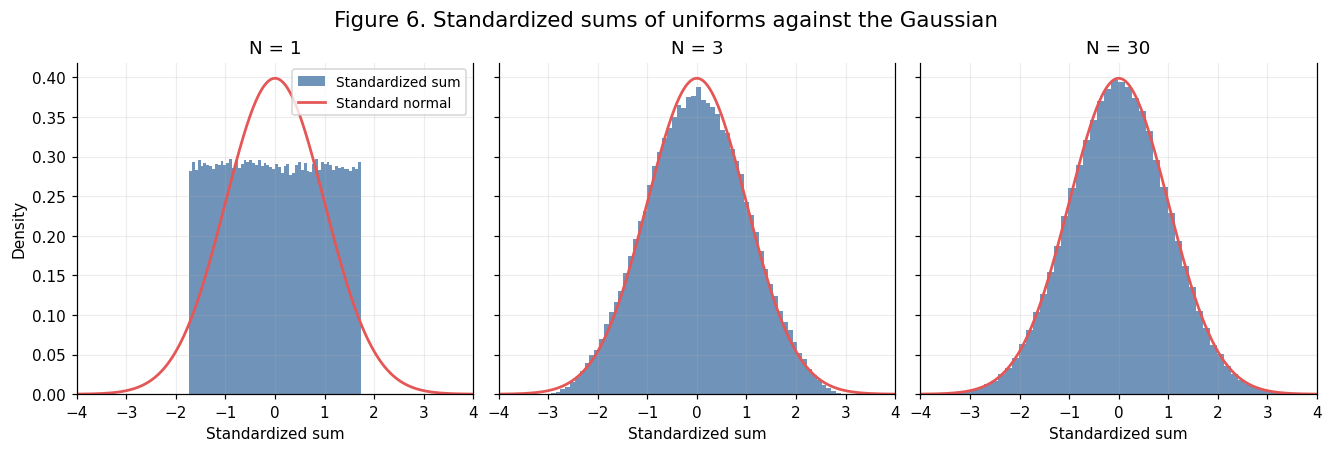

In [8]:
N5 = 200_000
critical5 = 1.36 / np.sqrt(N5)
uniform_ns5 = [1, 2, 3, 5, 10, 30]
pareto_ns5 = [1, 10, 100, 1000]
CHUNK5 = 5_000

def standardized_uniform_sums(n_terms):
    sums = rng5.random((N5, n_terms)).sum(axis=1)
    return (sums - n_terms / 2) / np.sqrt(n_terms / 12)

def pareto_sums(n_terms):
    sums = np.empty(N5)
    for start in range(0, N5, CHUNK5):
        sums[start:start + CHUNK5] = (1 + rng5.pareto(1.5, size=(CHUNK5, n_terms))).sum(axis=1)
    return sums

uniform_z5 = {n: standardized_uniform_sums(n) for n in uniform_ns5}
pareto_sums5 = {n: pareto_sums(n) for n in pareto_ns5}
# Population variance is infinite, so no theoretical scale exists: center with the true mean 3N
# and scale with the sample standard deviation of the sums.
pareto_z5 = {n: (s - 3 * n) / s.std(ddof=1) for n, s in pareto_sums5.items()}

ks_uniform5 = [ks_statistic(uniform_z5[n], stats.norm.cdf) for n in uniform_ns5]
zfine5 = np.linspace(-6, 6, 400_001)
exact_uniform5 = [np.max(np.abs(stats.irwinhall(n).cdf(n / 2 + zfine5 * np.sqrt(n / 12))
                                - stats.norm.cdf(zfine5))) for n in uniform_ns5]
ks_pareto5 = [ks_statistic(pareto_z5[n], stats.norm.cdf) for n in pareto_ns5]
table(['N', 'Mean of sum', 'Variance of sum', 'KS D vs N(0,1)', 'Exact distance', '95% cutoff', 'Decision'],
      [[n, n / 2, n / 12, d, e, critical5, 'Do not reject' if d < critical5 else 'Reject']
       for n, d, e in zip(uniform_ns5, ks_uniform5, exact_uniform5)])
table(['N', 'Mean of sum', 'Scale used (sample SD)', 'KS D vs N(0,1)', '95% cutoff', 'Decision'],
      [[n, 3 * n, pareto_sums5[n].std(ddof=1), d, critical5, 'Do not reject' if d < critical5 else 'Reject']
       for n, d in zip(pareto_ns5, ks_pareto5)])

# Slope of KS against N for the uniform case, and the stable-law scaling check for the Pareto case
slope5 = np.polyfit(np.log(uniform_ns5), np.log(exact_uniform5), 1)[0]
stable5 = {n: (pareto_sums5[n] - 3 * n) / n ** (1 / 1.5) for n in (100, 1000)}
d_stable5 = stats.ks_2samp(stable5[100], stable5[1000]).statistic
cutoff_stable5 = 1.36 * np.sqrt(2 / N5)
d_gauss_scale5 = stats.ks_2samp((pareto_sums5[100] - 300) / 100 ** .5,
                                (pareto_sums5[1000] - 3000) / 1000 ** .5).statistic
table(['Comparison, N = 100 vs N = 1000', 'Two-sample KS D', '95% cutoff'],
      [['Scaled by N^(1/2)', d_gauss_scale5, cutoff_stable5],
       ['Scaled by N^(2/3)', d_stable5, cutoff_stable5]])
print(f'Fitted log-log slope of the exact uniform distance against N: {slope5:.3f}.')

fig5, ax5 = plt.subplots(figsize=(7, 4.8), layout='constrained')
ax5.loglog(uniform_ns5, ks_uniform5, 'o-', color='#4c78a8', label='Uniform summands')
ax5.loglog(pareto_ns5, ks_pareto5, 's-', color='#e45756', label='Pareto summands (shape 1.5)')
ax5.loglog(uniform_ns5, exact_uniform5, ':', color='#4c78a8', label='Uniform, exact distance')
ax5.axhline(critical5, ls='--', color='#54a24b', label=f'95% cutoff = {critical5:.4f}')
ax5.set(xlabel='Number of summands N', ylabel='KS statistic vs standard normal')
ax5.legend(fontsize=9)
fig5.suptitle('Figure 5. KS distance to the Gaussian (2×10⁵ sums per N)', fontsize=14)
finish(fig5, 'figure_05')

fig6, axes6 = plt.subplots(1, 3, figsize=(12, 4), layout='constrained', sharey=True)
zgrid5 = np.linspace(-4, 4, 600)
for ax6, n in zip(axes6, (1, 3, 30)):
    ax6.hist(uniform_z5[n], bins=60, density=True, color='#4c78a8', alpha=.8, label='Standardized sum')
    ax6.plot(zgrid5, stats.norm.pdf(zgrid5), color='#e45756', lw=1.8, label='Standard normal')
    ax6.set(title=f'N = {n}', xlabel='Standardized sum', xlim=(-4, 4))
axes6[0].set_ylabel('Density')
axes6[0].legend(fontsize=9)
fig6.suptitle('Figure 6. Standardized sums of uniforms against the Gaussian', fontsize=14)
finish(fig6, 'figure_06')


Figure 5 plots the KS distance against $N$ on log-log axes, with the 95% cutoff drawn as a dashed line. Figure 6 shows the standardized uniform sums at $N=1,3,30$ against the standard normal density: the flat top at $N=1$ becomes a bump by $N=3$ and is visually indistinguishable from the bell curve at $N=30$.

For uniform summands the KS distances are **0.0584, 0.0172, 0.0096, 0.0066, 0.0048, 0.0017** for $N=1,2,3,5,10,30$. The exact Irwin–Hall distances are **0.0572, 0.0164, 0.0099, 0.0057, 0.0028, 0.00092**, and their fitted log-log slope is **-1.17**, so the decay is close to $1/N$ and faster than the $1/\sqrt N$ rate of the general bound, as expected for a symmetric summand. The sampled values sit at or above the exact ones because a KS statistic from $2\times10^5$ samples carries noise of about **0.001** on top of the true gap. Against the cutoff **0.0030411**, the tests reject for $N=1$ through $10$ and do not reject at $N=30$ (**0.0017**). These decisions apply to the frozen seed.

**Statistically versus practically different.** The 95% cutoff shrinks like $1/\sqrt{\text{samples}}$, so with enough samples any nonzero gap becomes detectable, and a rejection says only that the gap is not zero, not that it is large. A distance of **0.003** means the CDFs never differ by more than 0.3 percentage points, which is negligible for almost any probability estimate even if a sufficiently large sample would flag it. In this run $N=10$ is already within **0.0028** of the Gaussian by the exact calculation, essentially at the cutoff, yet its sampled statistic **0.0048** rejects only because of noise; the CLT is working, and the test is just sensitive.

For Pareto summands the KS distances are **0.4484, 0.3939, 0.4178, 0.3594** for $N=1,10,100,1000$: they stay in the range 0.36–0.45 and do not fall. Convergence stalls because the Pareto violates the **finite-variance hypothesis** of the CLT, since $E[P^2]=\infty$. A sum of $N$ such terms is dominated by its largest summand, so the sample scale is set by rare extremes and the bulk of the standardized sums piles up near zero with a few huge outliers, far from a bell curve.
The standardized sum converges instead to a **stable law** with index $\alpha=3/2$, with scale growing like $N^{1/\alpha}=N^{2/3}$ rather than $N^{1/2}$. Supporting this, the sums at $N=100$ and $N=1000$ differ by a two-sample KS distance of **0.2221** under $N^{1/2}$ scaling but only **0.0412** under $N^{2/3}$ scaling (cutoff **0.0043**): the $N^{2/3}$ scaling stabilizes the shape, though not yet to within the cutoff at these $N$, since convergence to a stable law is itself slow.

In [9]:
# Numerical conclusions for Steps 1–5.
for row in rows1 + rows2:
    print(f'{row[0]}: D = {row[2]:.7f}, cutoff = {row[3]:.7f}: {row[4]}')
for row in comparison_rows2:
    print(f'{row[0]}, inversion vs library: D = {row[2]:.7f}, '
          f'cutoff = {row[3]:.7f}: {row[4]}')
print(f'Step 3: density integral = {integral3:.10f}; KS D = {d3:.7f}, cutoff = {critical3:.7f}: '
      f"{'Do not reject' if d3 < critical3 else 'Reject'}")
for row in rows3:
    print(f'Step 3 {row[0]}: estimate = {row[1]:.7g}, theory = {row[2]:.7g}, SE = {row[4]:.3g}, z = {row[5]:.2f}')
print(f'Step 3 log-log slope: fitted {slope3:.4f}, theory {slope_theory}')
print(f'Step 4: largest Rayleigh raw-moment difference = {np.max(np.abs(diff4 / se4)):.3f} SE.')
print(f'Step 4 Pareto: mean = {pareto_stats4[-1, 0]:.6f}, sample variance = {pareto_stats4[-1, 1]:.6f} at N = {N4:,}.')
print('Step 5 uniform KS D: ' + ', '.join(f'N={n}: {d:.4f}' for n, d in zip(uniform_ns5, ks_uniform5))
      + f' (cutoff {critical5:.4f}); exact-distance slope {slope5:.2f}.')
print('Step 5 Pareto KS D: ' + ', '.join(f'N={n}: {d:.4f}' for n, d in zip(pareto_ns5, ks_pareto5)) + '.')


Uniform [0,1]: D = 0.0033703, cutoff = 0.0043007: Do not reject
Exponential, rate 1: D = 0.0017654, cutoff = 0.0043007: Do not reject
Standard Gaussian: D = 0.0034542, cutoff = 0.0043007: Do not reject
Rayleigh, scale 1: D = 0.0024282, cutoff = 0.0043007: Do not reject
Exponential, rate 1: D = 0.0038259, cutoff = 0.0043007: Do not reject
Rayleigh, scale 1: D = 0.0020791, cutoff = 0.0043007: Do not reject
Exponential, rate 1, inversion vs library: D = 0.0042500, cutoff = 0.0060821: Do not reject
Rayleigh, scale 1, inversion vs library: D = 0.0041700, cutoff = 0.0060821: Do not reject
Step 3: density integral = 1.0000000000; KS D = 0.0009189, cutoff = 0.0013600: Do not reject
Step 3 P[Y ≤ 1]: estimate = 0.682239, theory = 0.6826895, SE = 0.000465, z = -0.97
Step 3 P[Y ≤ 0.1]: estimate = 0.248191, theory = 0.2481704, SE = 0.000432, z = 0.05
Step 3 Median: estimate = 0.4554059, theory = 0.4549364, SE = 0.00106, z = 0.44
Step 3 Mean: estimate = 1.000613, theory = 1, SE = 0.00141, z = 0.43
S

## Step 6 — A threshold detector in Gaussian noise
**Contribution: Ibrahim Elsousi.** The following sections use the team's fixed seed and the existing `rng6` and `rng7` streams; Step 8 is analytic and needs no draws from `rng8`. All probabilities are **per decision**. Let $\sigma>0$, $A\ge0$, and declare a detection when $X>T$.

### Derive false-alarm and detection probabilities
Define $Q(z)=P(Z>z)=\int_z^\infty e^{-u^2/2}/\sqrt{2\pi}\,du$ for $Z\sim\mathcal N(0,1)$.
Under $H_0$, standardizing $X$ gives
\[
P_{FA}=P(X>T\mid H_0)=P\!\left(\frac{X}{\sigma}>\frac{T}{\sigma}\right)
=Q\!\left(\frac{T}{\sigma}\right).
\]
Under $H_1$, $X-A\sim\mathcal N(0,\sigma^2)$, so
\[
P_D=P(X>T\mid H_1)=P\!\left(\frac{X-A}{\sigma}>\frac{T-A}{\sigma}\right)
=Q\!\left(\frac{T-A}{\sigma}\right).
\]
Writing $\alpha=P_{FA}$ and $a=A/\sigma$, inversion gives
\[
\frac{T}{\sigma}=Q^{-1}(\alpha)=\Phi^{-1}(1-\alpha),\qquad
P_D=Q\!\left(Q^{-1}(\alpha)-a\right).
\]
The code uses `stats.norm.isf(alpha)` for the inverse, avoiding explicit subtraction of a very small tail from 1. The custom `q_function` itself uses only
\[
Q(z)=\tfrac12\operatorname{erfc}(z/\sqrt2),
\]
not numerical integration or a normal survival-function call. The three checks below include a probability below $10^{-7}$ and compare against SciPy's independent normal-tail implementation; 12 significant digits are displayed, exceeding the six-digit requirement.

In [10]:
START678 = perf_counter()
import csv
import json
RESULTDIR = Path('results')
RESULTDIR.mkdir(exist_ok=True)

def export_table678(name, headers, rows):
    table(headers, rows)
    with (RESULTDIR / f'{name}.csv').open('w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(headers)
        writer.writerows(rows)

q_args6 = np.array([0.0, 1.0, 5.2])
q_ours6 = q_function(q_args6)
q_ref6 = stats.norm.sf(q_args6)  # reference only; not q_function's implementation
np.testing.assert_allclose(q_ours6, q_ref6, rtol=5e-14, atol=0)
assert isinstance(q_function(0), np.ndarray)
np.testing.assert_array_equal(q_function([-np.inf, np.inf]), [1., 0.])
export_table678('step6_q_verification',
    ['x', 'Custom Q(x)', 'SciPy reference', 'Absolute error'],
    [[x, f'{a:.12g}', f'{b:.12g}', f'{abs(a-b):.3e}']
     for x, a, b in zip(q_args6, q_ours6, q_ref6)])

pfa6 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
a6 = 3.0
threshold6 = stats.norm.isf(pfa6)
pd6 = q_function(threshold6 - a6)
export_table678('step6_thresholds', ['P_FA', 'T / sigma', 'P_D at A / sigma = 3'],
                list(zip(pfa6, threshold6, pd6)))

| x | Custom Q(x) | SciPy reference | Absolute error |
|---|---|---|---|
| 0 | 0.5 | 0.5 | 0.000e+00 |
| 1 | 0.158655253931 | 0.158655253931 | 0.000e+00 |
| 5.2 | 9.96442631693e-08 | 9.96442631693e-08 | 1.191e-22 |

| P_FA | T / sigma | P_D at A / sigma = 3 |
|---|---|---|
| 0.01 | 2.326348 | 0.7497337 |
| 0.001 | 3.090232 | 0.4640513 |
| 0.0001 | 3.719016 | 0.2360654 |
| 1e-06 | 4.753424 | 0.0397646 |

### Monte Carlo verification and uncertainty
For $N$ independent Bernoulli detection indicators, $\hat p=k/N$ and
\[
\operatorname{SE}(\hat p)=\sqrt{\frac{p(1-p)}{N}},\qquad
\widehat{\operatorname{SE}}=\sqrt{\frac{\hat p(1-\hat p)}{N}}.
\]
For small $p$, the relative standard error is approximately $1/\sqrt{Np}$, so 10% requires about $100/p$ trials. We use **2,000,000 independent $H_0$ trials and 2,000,000 independent $H_1$ trials**, with $\sigma=1$ and $A=3$, to verify the $10^{-3}$ and $10^{-4}$ rows. At $10^{-4}$ the expected false-alarm count is 200 and the planned relative SE is 7.07%; at $10^{-3}$ it is 2.24%. The same independent measurement arrays are reused for the two thresholds, so estimates across rows are correlated, but the Bernoulli SE within each row is valid.

Each estimated probability below includes the count, $N$, theoretical and measured probability, achieved plug-in SE, relative SE, and residual in units of the theoretical SE. The separate distribution checks report a KS statistic and its $1.36/\sqrt N$ cutoff; they do not infer fit from a plotted curve.

In [11]:
N6 = 2_000_000
noise6 = rng6.standard_normal(N6)
signal6 = a6 + rng6.standard_normal(N6)
mc_rows6 = []
for alpha in (1e-3, 1e-4):
    threshold = float(stats.norm.isf(alpha))
    for label, samples, theory in [('P_FA', noise6, alpha),
                                    ('P_D', signal6, float(q_function(threshold-a6)))]:
        count = int(np.count_nonzero(samples > threshold))
        estimate = count / N6
        se_theory = np.sqrt(theory * (1-theory) / N6)
        se_measured = np.sqrt(estimate * (1-estimate) / N6)
        mc_rows6.append([alpha, label, N6, count, theory, estimate, se_measured,
                         se_measured / estimate, (estimate-theory) / se_theory])
export_table678('step6_monte_carlo',
    ['Design P_FA', 'Estimate', 'N', 'Count', 'Theory', 'Measured',
     'Measured SE', 'Relative SE', 'Residual / theoretical SE'], mc_rows6)
ks_rows6 = []
for label, samples, cdf in [('H0 Gaussian', noise6, stats.norm.cdf),
                           ('H1 Gaussian', signal6, stats.norm(loc=a6).cdf)]:
    d = ks_statistic(samples, cdf)
    critical = 1.36 / np.sqrt(N6)
    ks_rows6.append([label, N6, d, critical,
                    'Do not reject' if d < critical else 'Reject'])
export_table678('step6_ks', ['Distribution', 'N', 'KS D', '95% cutoff', 'Decision'], ks_rows6)
del noise6, signal6

| Design P_FA | Estimate | N | Count | Theory | Measured | Measured SE | Relative SE | Residual / theoretical SE |
|---|---|---|---|---|---|---|---|---|
| 0.001 | P_FA | 2000000 | 2031 | 0.001 | 0.0010155 | 2.252186e-05 | 0.0221781 | 0.6935279 |
| 0.001 | P_D | 2000000 | 927569 | 0.4640513 | 0.4637845 | 0.0003526248 | 0.0007603203 | -0.7566 |
| 0.0001 | P_FA | 2000000 | 195 | 0.0001 | 9.75e-05 | 6.98178e-06 | 0.071608 | -0.3535711 |
| 0.0001 | P_D | 2000000 | 471474 | 0.2360654 | 0.235737 | 0.0003001375 | 0.001273188 | -1.093576 |

| Distribution | N | KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| H0 Gaussian | 2000000 | 0.0006114988 | 0.0009616652 | Do not reject |
| H1 Gaussian | 2000000 | 0.0005830111 | 0.0009616652 | Do not reject |

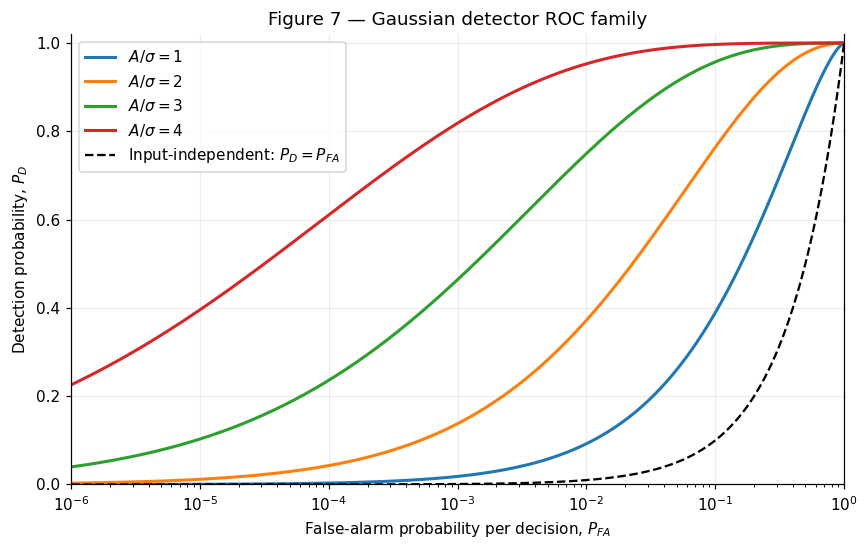

In [12]:
pfa_grid6 = np.logspace(-6, 0, 900)
fig7, ax7 = plt.subplots(figsize=(8.0, 5.1))
for amplitude in (1, 2, 3, 4):
    ax7.semilogx(pfa_grid6, q_function(stats.norm.isf(pfa_grid6)-amplitude),
                 label=fr'$A/\sigma={amplitude}$', lw=2)
ax7.semilogx(pfa_grid6, pfa_grid6, 'k--', lw=1.5, label='Input-independent: $P_D=P_{FA}$')
ax7.set(xlim=(1e-6, 1), ylim=(0, 1.02), xlabel='False-alarm probability per decision, $P_{FA}$',
        ylabel='Detection probability, $P_D$', title='Figure 7 — Gaussian detector ROC family')
ax7.legend(loc='upper left')
fig7.tight_layout()
finish(fig7, 'figure7_gaussian_roc')

**Figure 7 interpretation.** At the same false-alarm probability, a larger $A/\sigma$ increases detection; at a fixed $A/\sigma$, lowering the false-alarm budget raises the threshold and reduces detection. For $A/\sigma=3$, $P_{FA}=10^{-3}$ gives $T/\sigma=3.0902323$ and $P_D\approx0.4640513$, while $10^{-6}$ gives $T/\sigma=4.7534243$ and $P_D\approx0.0397646$, reproducing the Step 6 check values to their stated rounding. These are analytic values; Monte Carlo estimates and their measured standard errors are in the verification table.

**Input-independent detector (two sentences).** A receiver that declares detection with probability $r$ independently of its measurement has $P_D=P_{FA}=r$, so its ROC is the chance line joining $(0,0)$ to $(1,1)$ on linear axes. On this log-$P_{FA}$ plot it appears as the dashed curved baseline below the positive-amplitude ROCs; always-no and always-yes are its two endpoints, with $(0,0)$ outside the logarithmic axis.

## Step 7 — The envelope detector and noise mismatch
### Derive and invert the Rayleigh tail
For noise-only complex data $I+jQ$ with independent $I,Q\sim\mathcal N(0,\sigma^2)$, the magnitude $R=\sqrt{I^2+Q^2}$ is Rayleigh with **scale** $\sigma$. Its CDF is $F_R(r)=1-e^{-r^2/(2\sigma^2)}$ for $r\ge0$, hence for a nonnegative threshold
\[
P_{FA}=P(R>T)=1-F_R(T)=e^{-T^2/(2\sigma^2)}.
\]
Taking logs and the nonnegative square root gives
\[
\ln P_{FA}=-\frac{T^2}{2\sigma^2}
\quad\Longrightarrow\quad
\frac{T}{\sigma}=\sqrt{-2\ln P_{FA}}.
\]
Here $\operatorname{Var}(R)=(2-\pi/2)\sigma^2$, so the Rayleigh standard deviation is not the scale $\sigma$. The complex noise power is $E[R^2]=2\sigma^2$; a ratio of complex noise powers is therefore the same as the ratio of the underlying $\sigma^2$ values.

In [13]:
pfa7 = pfa6.copy()
threshold7 = np.sqrt(-2*np.log(pfa7))
export_table678('step7_thresholds', ['P_FA', 'T / sigma'], list(zip(pfa7, threshold7)))
N7 = 1_000_000
alpha7 = 1e-3
fixed_threshold7 = float(np.sqrt(-2*np.log(alpha7)))
noise7 = rng7.rayleigh(scale=1.0, size=N7)
count7 = int(np.count_nonzero(noise7 > fixed_threshold7))
estimate7 = count7 / N7
se7 = np.sqrt(estimate7 * (1-estimate7) / N7)
se_theory7 = np.sqrt(alpha7 * (1-alpha7) / N7)
export_table678('step7_monte_carlo',
    ['Theory P_FA', 'N', 'Count', 'Measured P_FA', 'Measured SE', 'Relative SE',
     'Residual / theoretical SE'],
    [[alpha7, N7, count7, estimate7, se7, se7/estimate7, (estimate7-alpha7)/se_theory7]])
d7 = ks_statistic(noise7, stats.rayleigh(scale=1).cdf)
critical7 = 1.36 / np.sqrt(N7)
export_table678('step7_ks', ['Distribution', 'N', 'KS D', '95% cutoff', 'Decision'],
    [['Rayleigh', N7, d7, critical7, 'Do not reject' if d7 < critical7 else 'Reject']])
del noise7

| P_FA | T / sigma |
|---|---|
| 0.01 | 3.034854 |
| 0.001 | 3.716922 |
| 0.0001 | 4.291932 |
| 1e-06 | 5.256522 |

| Theory P_FA | N | Count | Measured P_FA | Measured SE | Relative SE | Residual / theoretical SE |
|---|---|---|---|---|---|---|
| 0.001 | 1000000 | 1030 | 0.00103 | 3.207708e-05 | 0.0311428 | 0.949158 |

| Distribution | N | KS D | 95% cutoff | Decision |
|---|---|---|---|---|
| Rayleigh | 1000000 | 0.0007942096 | 0.00136 | Do not reject |

**Monte Carlo precision.** The Step 7 check uses $N=10^6$, so a design probability of $10^{-3}$ gives 1,000 expected false alarms and a theoretical SE of $3.1607\times10^{-5}$ (3.16% relative). The table reports the achieved count, probability, and measured SE for the team's frozen seed.

### Fixed threshold with an incorrect noise-power estimate
Let $\sigma_0$ be the assumed scale, $\sigma_t$ the true scale, and
\[
\Delta=10\log_{10}\!\left(\frac{\sigma_t^2}{\sigma_0^2}\right),\qquad
r=10^{\Delta/10},\qquad \sigma_t=\sigma_0\sqrt r.
\]
Keep $T=\sigma_0\sqrt{-2\ln\alpha}$ fixed at the $\alpha=10^{-3}$ design setting. Substitution yields
\[
P_{FA,\mathrm{actual}}
=\exp\!\left[-\frac{\sigma_0^2(-2\ln\alpha)}{2\sigma_t^2}\right]
=\exp\!\left(\frac{\ln\alpha}{r}\right)
=\alpha^{10^{-\Delta/10}},
\qquad
\frac{P_{FA,\mathrm{actual}}}{\alpha}=\alpha^{10^{-\Delta/10}-1}.
\]
The exponent uses **10** for the power ratio; the corresponding standard-deviation ratio uses $10^{\Delta/20}$.

| Noise power error (dB) | True / assumed power | Actual P_FA | Actual / design P_FA |
|---|---|---|---|
| -1 | 0.7943282 | 0.0001671952 | 0.1671952 |
| 0 | 1 | 0.001 | 1 |
| 1 | 1.258925 | 0.004140143 | 4.140143 |
| 2 | 1.584893 | 0.01279758 | 12.79758 |
| 3 | 1.995262 | 0.03136449 | 31.36449 |

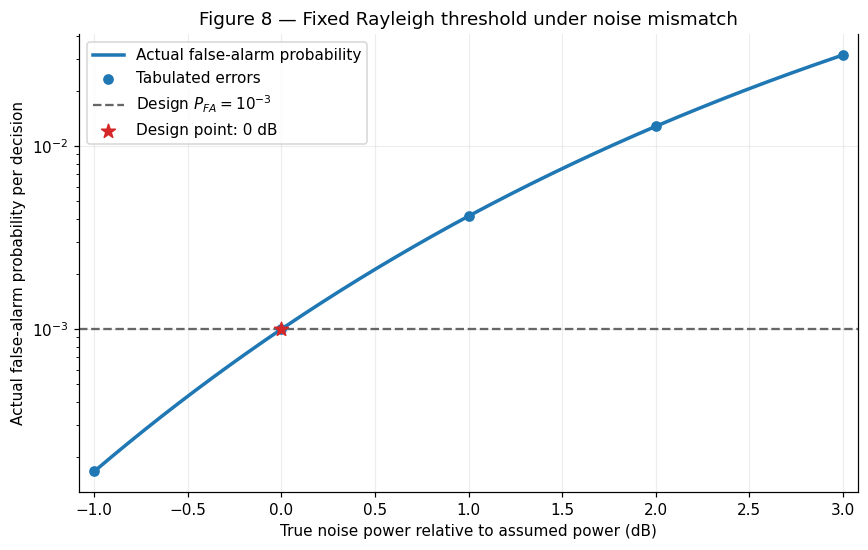

In [14]:
error_db7 = np.array([-1, 0, 1, 2, 3], dtype=float)
actual_pfa7 = alpha7 ** (10 ** (-error_db7 / 10))
export_table678('step7_noise_mismatch',
    ['Noise power error (dB)', 'True / assumed power', 'Actual P_FA', 'Actual / design P_FA'],
    list(zip(error_db7, 10**(error_db7/10), actual_pfa7, actual_pfa7/alpha7)))
error_grid7 = np.linspace(-1, 3, 401)
fig8, ax8 = plt.subplots(figsize=(8.0, 5.1))
ax8.semilogy(error_grid7, alpha7**(10**(-error_grid7/10)), lw=2.3, label='Actual false-alarm probability')
ax8.scatter(error_db7, actual_pfa7, color='tab:blue', zorder=4, label='Tabulated errors')
ax8.axhline(alpha7, ls='--', color='0.4', label='Design $P_{FA}=10^{-3}$')
ax8.scatter([0], [alpha7], s=90, marker='*', color='tab:red', zorder=5, label='Design point: 0 dB')
ax8.set(xlabel='True noise power relative to assumed power (dB)',
        ylabel='Actual false-alarm probability per decision',
        title='Figure 8 — Fixed Rayleigh threshold under noise mismatch', xlim=(-1.08, 3.08))
ax8.legend(loc='upper left')
fig8.tight_layout()
finish(fig8, 'figure8_noise_mismatch')

**Figure 8 interpretation.** A +1 dB noise-power error increases $P_{FA}$ from $0.001$ to $0.00414014$ (4.14014 times), and +3 dB increases it to $0.03136449$ (31.36449 times), matching the assignment's rounded checks. A -1 dB error reduces it to $0.000167195$ (0.167195 times); the fixed threshold is then conservative for false alarms, though any detection claim would also require a signal-present envelope model.

A fixed threshold can produce large changes in nuisance detections when temperature, interference, or clutter changes the noise level, because it samples the steep distribution tail. A designer can track the noise scale using representative, preferably signal-free reference measurements and adapt the threshold, as in constant-false-alarm-rate (CFAR) processing, with a guard margin for bounded estimation error. Reference-window contamination and non-Rayleigh clutter must be checked because the tail formula assumes a Rayleigh noise distribution; more samples alone cannot repair a wrong model. Where adaptation is unavailable, a threshold chosen for the maximum credible noise level limits false alarms but sacrifices sensitivity, quantified next for the Gaussian model.

## Step 8 — Choosing the operating point
### Required signal-to-noise ratio
For the Gaussian detector, write $\alpha=P_{FA}$, $\beta=P_D$, and $a=A/\sigma$. From Step 6,
\[
\beta=Q\!\left(Q^{-1}(\alpha)-a\right)
\quad\Longrightarrow\quad
Q^{-1}(\beta)=Q^{-1}(\alpha)-a
\quad\Longrightarrow\quad
\boxed{a=Q^{-1}(\alpha)-Q^{-1}(\beta)
=\Phi^{-1}(1-\alpha)+\Phi^{-1}(\beta).}
\]
$A/\sigma$ is an amplitude ratio; the corresponding power SNR is $\rho=A^2/\sigma^2=a^2$, and
\[
\mathrm{SNR}_{dB}=10\log_{10}\rho=20\log_{10}a.
\]
The table below gives both linear quantities to remove any ambiguity in the word SNR. The figure uses $10^{-6}\le P_{FA}\le10^{-2}$, where all required amplitude ratios for the three requested $P_D$ values are positive.

**Correction to the supplied Step 8 check.** For $P_D=0.9$, $Q^{-1}(0.9)=-1.2815516$, so this negative number must be **subtracted**, or equivalently $1.2815516$ must be added to the false-alarm quantile. Thus $P_{FA}=10^{-3}$ requires $a=4.3717839$ (**12.81317 dB**), and $10^{-6}$ requires $a=6.0349759$ (**15.61351 dB**). The handout's $a\approx1.81$ and $3.47$ instead yield $P_D\approx0.10$, indicating a sign error; their stated dB values correspond to those same incorrect amplitude ratios. The correct SNR cost of reducing $P_{FA}$ from $10^{-3}$ to $10^{-6}$ at 90% detection is **2.80034 dB**. The substitution table below explicitly verifies this discrepancy rather than forcing agreement with it.

In [15]:
beta8 = 0.9
a_required8 = stats.norm.isf(pfa6) - stats.norm.isf(beta8)
snr_db8 = 20*np.log10(a_required8)
export_table678('step8_required_snr',
    ['P_FA', 'Required A / sigma', 'Power SNR (A / sigma)^2', 'SNR (dB)', 'Back-substituted P_D'],
    list(zip(pfa6, a_required8, a_required8**2, snr_db8,
             q_function(stats.norm.isf(pfa6)-a_required8))))
np.testing.assert_allclose(q_function(stats.norm.isf(pfa6)-a_required8), beta8, atol=1e-14)
export_table678('step8_handout_correction',
    ['P_FA', 'Handout A / sigma', 'P_D from handout ratio', 'Correct A / sigma for P_D = 0.9'],
    [[p, a, float(q_function(stats.norm.isf(p)-a)), float(stats.norm.isf(p)-stats.norm.isf(.9))]
     for p, a in [(1e-3, 1.81), (1e-6, 3.47)]])

# Conditional operating choices for the assignment's single-measurement model.
operating8 = [('Smoke alarm', 1e-2, 0.99), ('Radar + tracker', 1e-6, 0.90)]
operating_rows8 = []
for name, alpha, beta in operating8:
    t = float(stats.norm.isf(alpha))
    a = t - float(stats.norm.isf(beta))
    operating_rows8.append([name, alpha, beta, t, a, a*a, 20*np.log10(a)])
export_table678('step8_operating_points',
    ['System', 'Chosen P_FA', 'Chosen P_D', 'T / sigma', 'A / sigma', 'Power SNR', 'SNR (dB)'],
    operating_rows8)

| P_FA | Required A / sigma | Power SNR (A / sigma)^2 | SNR (dB) | Back-substituted P_D |
|---|---|---|---|---|
| 0.01 | 3.607899 | 13.01694 | 11.14509 | 0.9 |
| 0.001 | 4.371784 | 19.11249 | 12.81317 | 0.9 |
| 0.0001 | 5.000568 | 25.00568 | 13.98039 | 0.9 |
| 1e-06 | 6.034976 | 36.42093 | 15.61351 | 0.9 |

| P_FA | Handout A / sigma | P_D from handout ratio | Correct A / sigma for P_D = 0.9 |
|---|---|---|---|
| 0.001 | 1.81 | 0.1002317 | 4.371784 |
| 1e-06 | 3.47 | 0.09967173 | 6.034976 |

| System | Chosen P_FA | Chosen P_D | T / sigma | A / sigma | Power SNR | SNR (dB) |
|---|---|---|---|---|---|---|
| Smoke alarm | 0.01 | 0.99 | 2.326348 | 4.652696 | 21.64758 | 13.35409 |
| Radar + tracker | 1e-06 | 0.9 | 4.753424 | 6.034976 | 36.42093 | 15.61351 |

### Two conditional engineering recommendations
**Smoke alarm:** choose $P_{FA}=10^{-2}$ and $P_D=0.99$, placing the detector toward the high-detection, higher-false-alarm part of its ROC; this gives $T=2.32635\sigma$ and requires $A/\sigma=4.65270$ (**13.35409 dB**). A missed fire has a severe consequence, so this classroom operating point prioritizes detection while recognizing that repeated nuisance alerts undermine trust and can cause users to disable the alarm.

**Radar surveillance feeding a tracker:** choose $P_{FA}=10^{-6}$ and $P_D=0.90$, placing the detector toward the low-false-alarm part of its ROC; this gives $T=4.75342\sigma$ and requires $A/\sigma=6.03498$ (**15.61351 dB**). The very low false-alarm setting limits phantom-track workload, while 90% single-scan detection allows occasional misses that a tracker can partly recover on later scans.

These choices are **per-decision illustrative requirements**, not hardware certification or universal operating standards. For $M$ independent noise-only opportunities, the expected false-alarm count is $M\alpha$ and the probability of at least one is $1-(1-\alpha)^M$; a smoke detector making one independent decision every second at $\alpha=0.01$ would have 864 expected nuisance triggers per day, making this raw single-measurement setting unacceptable as a direct household-alert rule. Its suitability would require a much lower effective decision rate or a separately designed and validated confirmation stage, which also changes latency and miss probability. Similarly, $10^{-6}$ yields one expected raw false hit per million tested radar cells, so the radar's cell rate and track-initiation logic matter. These assumptions must be resolved before adopting either numeric choice.

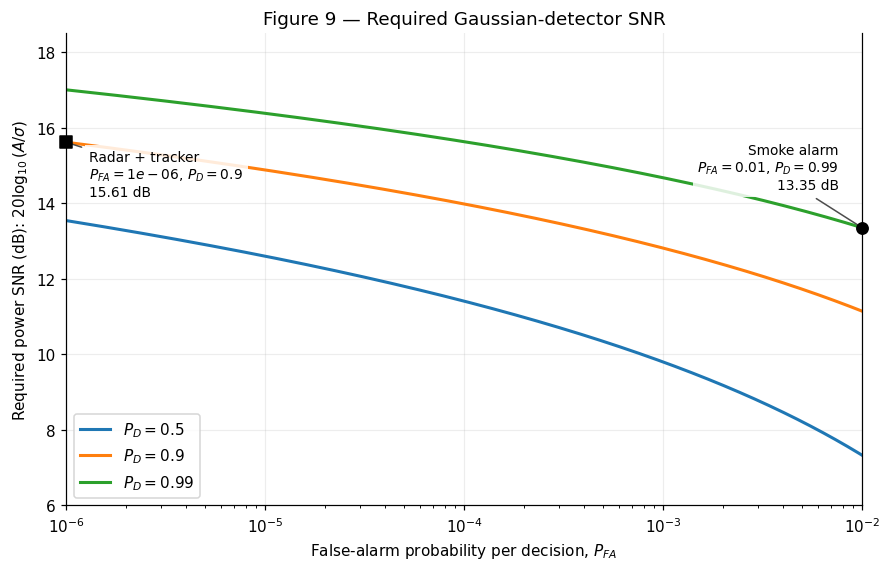

In [16]:
pfa_grid8 = np.logspace(-6, -2, 600)
fig9, ax9 = plt.subplots(figsize=(8.2, 5.3))
for beta in (.5, .9, .99):
    required = stats.norm.isf(pfa_grid8) - stats.norm.isf(beta)
    ax9.semilogx(pfa_grid8, 20*np.log10(required), lw=2, label=fr'$P_D={beta:g}$')
for row, marker, offset in zip(operating_rows8, ['o', 's'], [(-15, 25), (15, -35)]):
    name, alpha, beta, t, a, power, db = row
    ax9.scatter([alpha], [db], marker=marker, color='black', s=55, zorder=5, clip_on=False)
    ax9.annotate(f'{name}\n$P_{{FA}}={alpha:g}$, $P_D={beta:g}$\n{db:.2f} dB',
                 xy=(alpha, db), xytext=offset, textcoords='offset points',
                 ha='right' if alpha > 1e-4 else 'left', fontsize=9,
                 arrowprops={'arrowstyle': '-', 'color': '0.3'},
                 bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85, 'pad': 3})
ax9.set(xlim=(1e-6, 1e-2), ylim=(6, 18.5), xlabel='False-alarm probability per decision, $P_{FA}$',
        ylabel=r'Required power SNR (dB): $20\log_{10}(A/\sigma)$',
        title='Figure 9 — Required Gaussian-detector SNR')
ax9.legend(loc='lower left')
fig9.tight_layout()
finish(fig9, 'figure9_required_snr')

**Figure 9 interpretation.** Lowering $P_{FA}$ or increasing $P_D$ raises the required SNR because each demands more separation between the signal-present and noise-only distributions. For 90% detection, tightening the false-alarm probability from $10^{-3}$ to $10^{-6}$ increases the required SNR from 12.81317 to 15.61351 dB, a 2.80034 dB penalty. The marked smoke-alarm point accepts more per-decision false alarms to target 99% detection, whereas the radar point spends more SNR on false-alarm rejection and accepts 90% detection; these values assume the noise scale is known exactly.

### A threshold margin for +1 dB noise-power uncertainty
To keep the false-alarm rate no greater than its design value when the true noise power can be 1 dB above the estimate, budget the upper standard deviation
\[
c=10^{1/20}=1.12201845,\qquad \sigma_{\max}=c\sigma_0.
\]
Both the Gaussian and Rayleigh thresholds are proportional to their noise scale, so increase their nominal threshold by **12.201845%**:
\[
T_{\mathrm{margin}}=cT_0,\qquad \Delta T=(c-1)T_0.
\]
For example, Step 7's envelope threshold increases from $3.71692\sigma_0$ to $4.17046\sigma_0$. At true noise power +1 dB this restores $P_{FA}=10^{-3}$; at nominal noise its false-alarm probability becomes $\alpha^{c^2}\approx1.67195\times10^{-4}$. No envelope detection probability is inferred, because Step 7 specifies only its noise-only distribution.

For the **Gaussian recommendations**, let $z=Q^{-1}(\alpha)$ and hold the physical signal amplitude fixed at $A=a\sigma_0$, with $a$ chosen for the original $\beta$. The margin's detection cost depends on which noise level is present:
\[
\begin{aligned}
P_D\text{ at nominal noise}&=Q(cz-a),\\
P_D\text{ at +1 dB true noise}&=Q\!\left(\frac{c\sigma_0z-a\sigma_0}{c\sigma_0}\right)=Q(z-a/c).
\end{aligned}
\]
At the worst-case noise level, $P_{FA}=Q(z)=\alpha$ exactly. Restoring the original $\beta$ under that noise requires increasing $A$ by $c$, which adds **1 dB to the required power SNR measured against the assumed noise**; the SNR against the actual, higher noise then equals the original requirement. The table distinguishes the nominal-noise margin penalty from the combined margin-and-noise penalty, and reports losses in percentage points.

In [17]:
c8 = 10**(1/20)
margin_rows8 = []
for name, alpha, beta, z, a, power, db in operating_rows8:
    pd_nominal = float(q_function(c8*z-a))
    pd_worst = float(q_function(z-a/c8))
    margin_rows8.append([name, c8*z, (c8-1)*z, beta, pd_nominal, 100*(beta-pd_nominal),
                         pd_worst, 100*(beta-pd_worst), float(q_function(z)),
                         c8*a, db+1])
export_table678('step8_noise_margin',
    ['System', 'Margin T / sigma0', 'Added T / sigma0', 'Original P_D',
     'P_D nominal noise', 'Nominal loss (percentage points)', 'P_D at +1 dB',
     '+1 dB loss (percentage points)', 'P_FA at +1 dB',
     'A / sigma0 to restore original P_D', 'Restored SNR vs assumed noise (dB)'], margin_rows8)
print(f'Envelope margin: T / sigma0 = {c8*fixed_threshold7:.7f}; '
      f'nominal P_FA = {alpha7**(c8*c8):.9g}; +1 dB P_FA = {alpha7:.9g}.')
for name, alpha, beta, z, a, power, db in operating_rows8:
    np.testing.assert_allclose(q_function((c8*z)/(c8)), alpha, rtol=5e-14)
    np.testing.assert_allclose(q_function(z-(c8*a)/c8), beta, atol=1e-14)

| System | Margin T / sigma0 | Added T / sigma0 | Original P_D | P_D nominal noise | Nominal loss (percentage points) | P_D at +1 dB | +1 dB loss (percentage points) | P_FA at +1 dB | A / sigma0 to restore original P_D | Restored SNR vs assumed noise (dB) |
|---|---|---|---|---|---|---|---|---|---|---|
| Smoke alarm | 2.610205 | 0.2838574 | 0.99 | 0.9794485 | 1.055145 | 0.9656488 | 2.435122 | 0.01 | 5.22041 | 14.35409 |
| Radar + tracker | 5.33343 | 0.5800055 | 0.9 | 0.7585189 | 14.14811 | 0.7340977 | 16.59023 | 1e-06 | 6.771354 | 16.61351 |

Envelope margin: T / sigma0 = 4.1704553; nominal P_FA = 0.000167195184; +1 dB P_FA = 0.001.


**Margin recommendation.** With the signal amplitude fixed, the smoke-alarm threshold becomes $2.61021\sigma_0$; its detection probability falls from 0.99 to **0.97945** at nominal noise (1.05515 percentage points), and to **0.96565** at +1 dB true noise (2.43512 percentage points). The radar threshold becomes $5.33343\sigma_0$; detection falls from 0.90 to **0.75852** at nominal noise (14.14811 percentage points), and to **0.73410** at +1 dB true noise (16.59023 percentage points). This large radar sensitivity penalty favors a reliable adaptive noise estimate; a fixed margin alone protects false alarms but cannot also preserve detection without additional signal-to-noise budget. If the original detection targets must hold at +1 dB, budget **14.35409 dB** for smoke and **16.61351 dB** for radar relative to the assumed noise.

**The one question before committing:** What system-level nuisance-alert budget and maximum missed-event probability over the required response time must this detector satisfy, after accounting for its decision rate and any confirmation or tracking logic? For the smoke alarm, the product's system-safety requirements owner must answer it; for radar, the surveillance mission/customer requirements owner must answer it with operator and tracker input. That answer determines whether these illustrative per-decision operating points are acceptable or must move on the ROC.

### Acceptance notes for Steps 6–8
- Figure 7: ROC curves for $A/\sigma=1,2,3,4$, chance baseline, required log axis, and interpretation.
- Figure 8: noise-power errors -1 through +3 dB, log probability axis, design point, and interpretation.
- Figure 9: $P_D=0.5,0.9,0.99$ curves, labeled operating points, and interpretation.
- Required derivations appear in Markdown with intermediate steps; tables are printed and exported to CSV.
- Every Monte Carlo estimate includes its trial count and standard error; distribution checks include KS statistics and critical values.
- Step 6 and Step 7 check values are reproduced; the incompatible Step 8 check is explicitly diagnosed and verified by substitution.
- The original team seed and the preallocated step streams are retained. Restart the kernel and run all to reproduce results; manually rerunning a stochastic cell alone advances that step's generator.

In [18]:
RUNTIME678 = perf_counter() - START678
TOTAL_RUNTIME = perf_counter() - START
runtime678 = {
    'seed': int(SEED),
    'completed_scope': 'Steps 1-8; optional bonuses not implemented',
    'steps_6_8_seconds': RUNTIME678,
    'complete_notebook_seconds': TOTAL_RUNTIME,
    'under_300_seconds': bool(TOTAL_RUNTIME < 300),
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'scipy': scipy.__version__,
    'matplotlib': matplotlib.__version__,
}
(RESULTDIR / 'runtime.json').write_text(json.dumps(runtime678, indent=2) + '\n')
print(f'Completed scope: Steps 1–8. Seed: {SEED}.')
print(f'Steps 6–8: {RUNTIME678:.2f} s; complete notebook: {TOTAL_RUNTIME:.2f} s.')
print(f'Under five minutes: {TOTAL_RUNTIME < 300}. Optional bonuses remain separate work.')

Completed scope: Steps 1–8. Seed: 1274601137.
Steps 6–8: 2.65 s; complete notebook: 124.00 s.
Under five minutes: True. Optional bonuses remain separate work.
